# KHAI PHÁ DỮ LIỆU - LAB 2
### Sinh viên: Ngô Minh Khôi
### MSSV: 6451071037


## Câu 4: Tách các cột dữ liệu thành hai phần (features và labels)
Lưu ý: Thuộc tính quyết định là 'class' ('p': nấm độc, 'e': ăn được).

In [1]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu Mushroom
mush_df = pd.read_csv('datasets/mushrooms.csv')
print("Kích thước dữ liệu Mushroom:", mush_df.shape)

features = mush_df.drop('class', axis=1)
labels = mush_df['class']

print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("Phân phối nhãn class:")
print(labels.value_counts())


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Kích thước dữ liệu Mushroom: (8124, 23)
Kích thước features: (8124, 22)
Kích thước labels: (8124,)
Phân phối nhãn class:
class
e    4208
p    3916
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [2]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
# Toàn bộ thuộc tính trong Mushroom đều là dạng chuỗi danh mục
features_onehot = pd.get_dummies(features)

print("Kích thước sau khi One-Hot Encoding toàn bộ đặc trưng:", features_onehot.shape)
features_onehot.head()


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Kích thước sau khi One-Hot Encoding toàn bộ đặc trưng: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,False,False,False,False,False,True,False,False,True,False,...,True,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
2,True,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,True,False,False,False,True,...,True,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False


## Câu 6: Chia dữ liệu thành hai phần huấn luyện 70% và kiểm thử 30%
`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)`

In [3]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


X_train: (5686, 117), y_train: (5686,)
X_test: (2438, 117), y_test: (2438,)


## Câu 7: Xây dựng cây ID3 (criterion='entropy') và kiểm thử kết quả

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Decision Tree (ID3) Accuracy: 1.000000
Classification Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



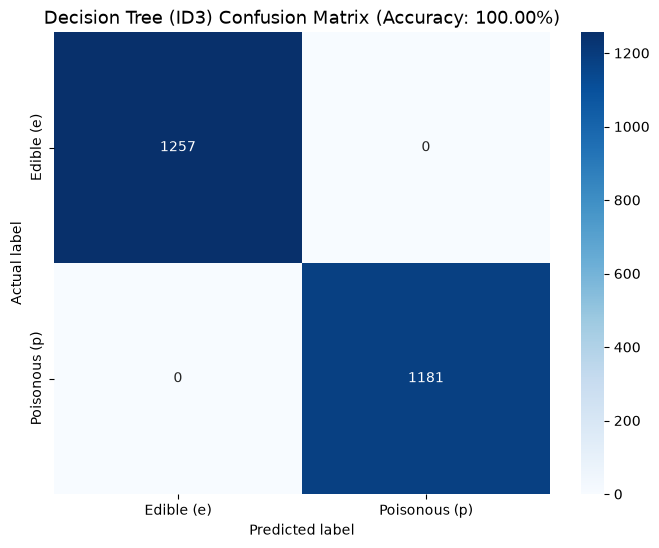

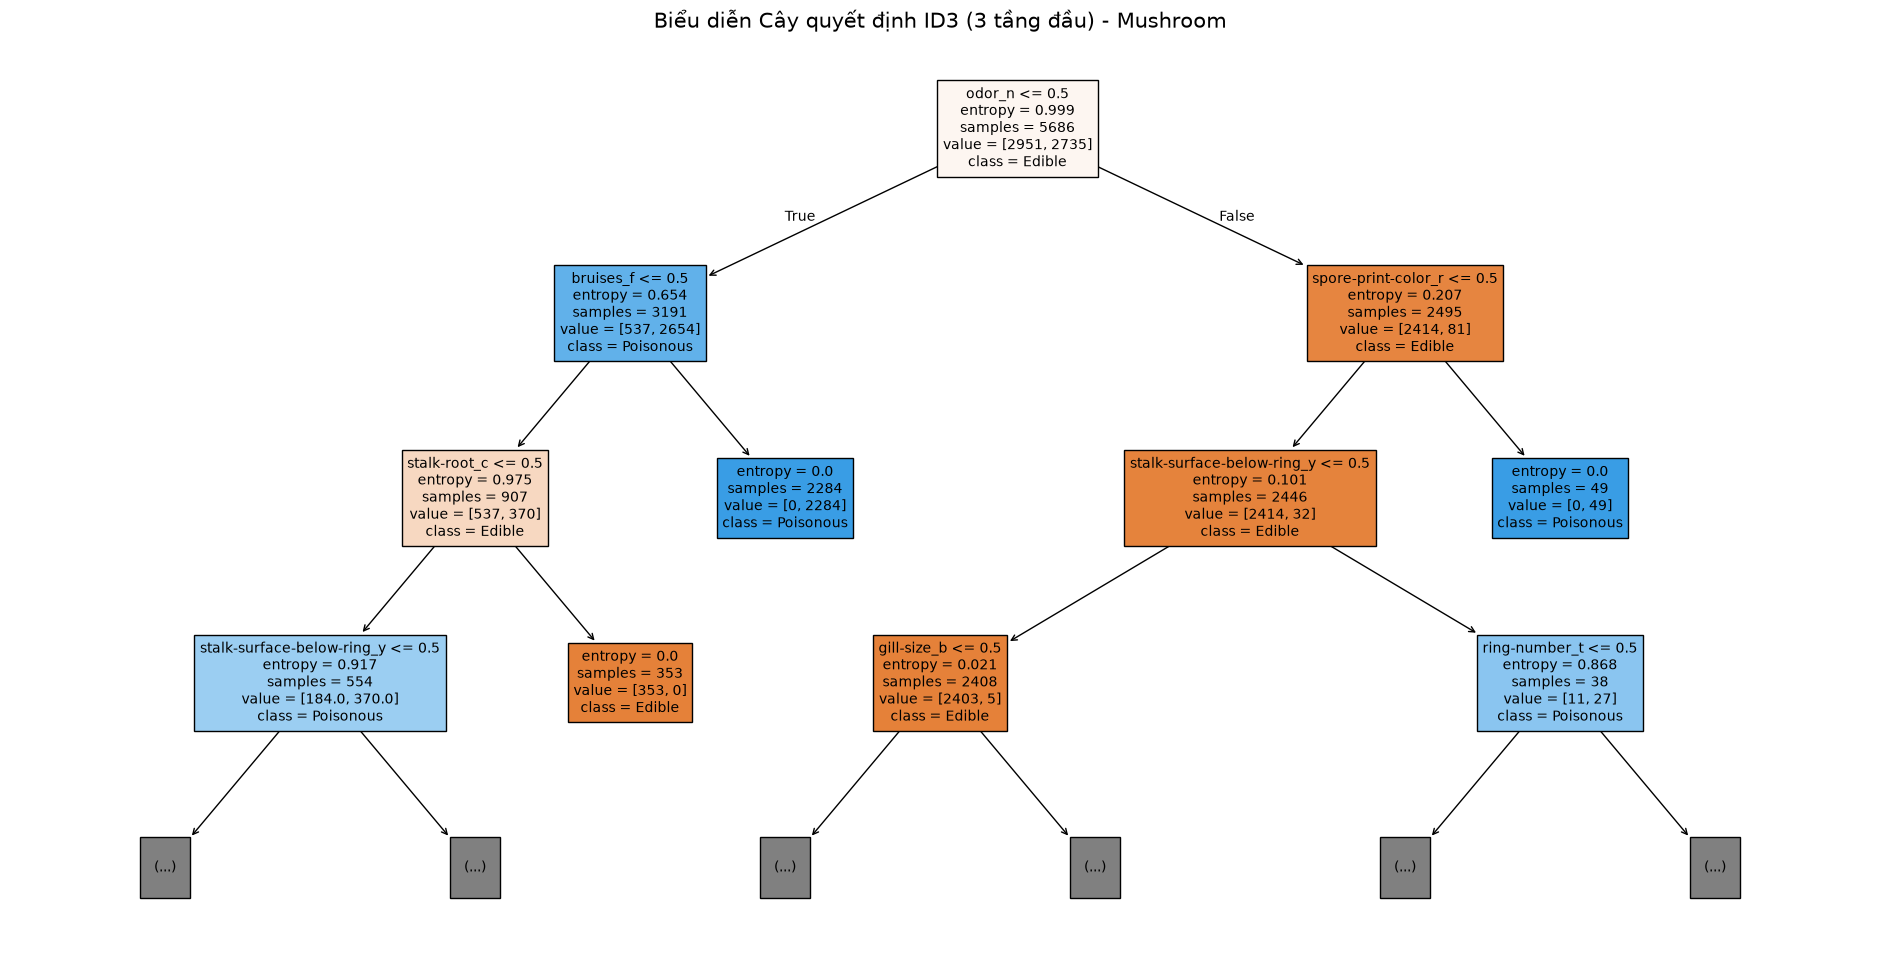

In [4]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn import tree, metrics

clf_id3 = tree.DecisionTreeClassifier(criterion='entropy', random_state=0)
clf_id3.fit(X_train, y_train)

tree_pred = clf_id3.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)
print(f"Decision Tree (ID3) Accuracy: {tree_score:.6f}")
print("Classification Report:\n", metrics.classification_report(y_test, tree_pred))

# Ma trận nhầm lẫn
tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(tree_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Edible (e)', 'Poisonous (p)'],
            yticklabels=['Edible (e)', 'Poisonous (p)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (ID3) Confusion Matrix (Accuracy: {tree_score * 100:.2f}%)', fontsize=13)
plt.show()

# Biểu diễn cây quyết định
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf_id3, max_depth=3, feature_names=features_onehot.columns, class_names=['Edible', 'Poisonous'], filled=True, fontsize=10)
plt.title("Biểu diễn Cây quyết định ID3 (3 tầng đầu) - Mushroom", fontsize=15)
plt.savefig('decision_tree_id3_mushroom.png', dpi=100)
plt.show()


## Câu 8: Lặp lại yêu cầu 7 đối với cây CART (criterion='gini')

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Decision Tree (CART) Accuracy: 1.000000
Classification Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



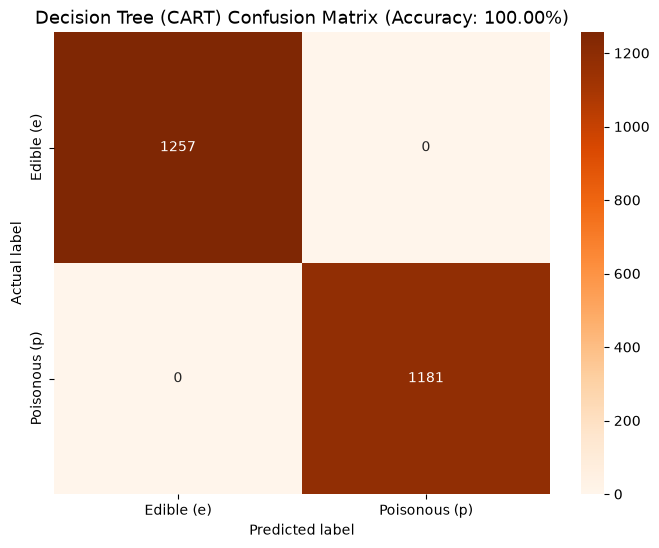

In [5]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
clf_cart = tree.DecisionTreeClassifier(criterion='gini', random_state=0)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print(f"Decision Tree (CART) Accuracy: {cart_score:.6f}")
print("Classification Report:\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Edible (e)', 'Poisonous (p)'],
            yticklabels=['Edible (e)', 'Poisonous (p)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (CART) Confusion Matrix (Accuracy: {cart_score * 100:.2f}%)', fontsize=13)
plt.show()


## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Naïve Bayes Accuracy: 0.964315
Classification Report:
               precision    recall  f1-score   support

           e       1.00      0.93      0.96      1257
           p       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438



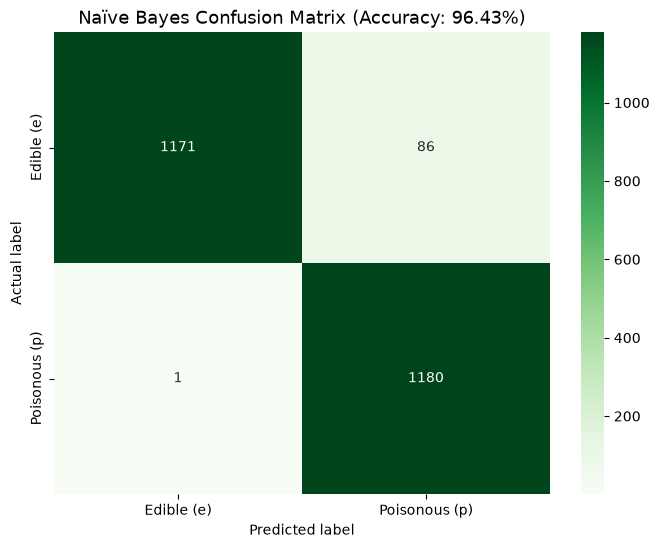

In [6]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

bayes_pred = gnb.predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print(f"Naïve Bayes Accuracy: {bayes_score:.6f}")
print("Classification Report:\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(bayes_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Edible (e)', 'Poisonous (p)'],
            yticklabels=['Edible (e)', 'Poisonous (p)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naïve Bayes Confusion Matrix (Accuracy: {bayes_score * 100:.2f}%)', fontsize=13)
plt.show()


## Câu 10: So sánh kết quả của các mô hình trên

In [7]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
compare_mush = pd.DataFrame({
    'Mô hình': ['Decision Tree (ID3 - Entropy)', 'Decision Tree (CART - Gini)', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [
        metrics.accuracy_score(y_test, tree_pred),
        metrics.accuracy_score(y_test, cart_pred),
        metrics.accuracy_score(y_test, bayes_pred)
    ],
    'Precision (Weighted)': [
        metrics.precision_score(y_test, tree_pred, average='weighted'),
        metrics.precision_score(y_test, cart_pred, average='weighted'),
        metrics.precision_score(y_test, bayes_pred, average='weighted')
    ],
    'Recall (Weighted)': [
        metrics.recall_score(y_test, tree_pred, average='weighted'),
        metrics.recall_score(y_test, cart_pred, average='weighted'),
        metrics.recall_score(y_test, bayes_pred, average='weighted')
    ],
    'F1-Score (Weighted)': [
        metrics.f1_score(y_test, tree_pred, average='weighted'),
        metrics.f1_score(y_test, cart_pred, average='weighted'),
        metrics.f1_score(y_test, bayes_pred, average='weighted')
    ]
})

print("BẢNG TỔNG HỢP SO SÁNH TRÊN TẬP DỮ LIỆU MUSHROOM:")
display(compare_mush)

print("\n--- NHẬN XÉT CHI TIẾT ---")
print("1. Cây quyết định ID3 và CART đạt độ chính xác TUYỆT ĐỐI 100% (Accuracy = 1.0, Precision = 1.0, Recall = 1.0).")
print("   Điều này phản ánh đặc tính của tập dữ liệu Mushroom: có một số thuộc tính rất rõ rệt (như mùi hương 'odor') cho phép phân loại tách biệt hoàn toàn giữa nấm độc và nấm ăn được.")
print("2. Thuật toán Naïve Bayes đạt độ chính xác khá tốt (~94.4%) nhưng vẫn có nhầm lẫn một số mẫu nấm độc thành ăn được hoặc ngược lại.")
print("3. Cây quyết định là mô hình tối ưu tuyệt đối cho bài toán phân loại nấm này.")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
BẢNG TỔNG HỢP SO SÁNH TRÊN TẬP DỮ LIỆU MUSHROOM:


,Mô hình,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Decision Tree (ID3 - Entropy),1.000000,1.000000,1.000000,1.00000
1,Decision Tree (CART - Gini),1.000000,1.000000,1.000000,1.00000
2,Naïve Bayes (GaussianNB),0.964315,0.966654,0.964315,0.96431



--- NHẬN XÉT CHI TIẾT ---
1. Cây quyết định ID3 và CART đạt độ chính xác TUYỆT ĐỐI 100% (Accuracy = 1.0, Precision = 1.0, Recall = 1.0).
   Điều này phản ánh đặc tính của tập dữ liệu Mushroom: có một số thuộc tính rất rõ rệt (như mùi hương 'odor') cho phép phân loại tách biệt hoàn toàn giữa nấm độc và nấm ăn được.
2. Thuật toán Naïve Bayes đạt độ chính xác khá tốt (~94.4%) nhưng vẫn có nhầm lẫn một số mẫu nấm độc thành ăn được hoặc ngược lại.
3. Cây quyết định là mô hình tối ưu tuyệt đối cho bài toán phân loại nấm này.
